In [20]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import silhouette_score

In [21]:
def plot_clusters(X, y=None):
  plt.scatter(X[:, 0], X[:, 1], c=y, s=10)
  plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker='x', s=100, c='r')


In [22]:
# Datasets
blob_centers = np.array(
    [[ 0.2,  2.3],
     [-1.5 ,  2.3],
     [-2.8,  1.8],
     [-2.8,  2.8],
     [-2.8,  1.3]])
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])

X, y = make_blobs(n_samples=2000, centers=blob_centers,
                  cluster_std=blob_std, random_state=7)

In [23]:
# X, y

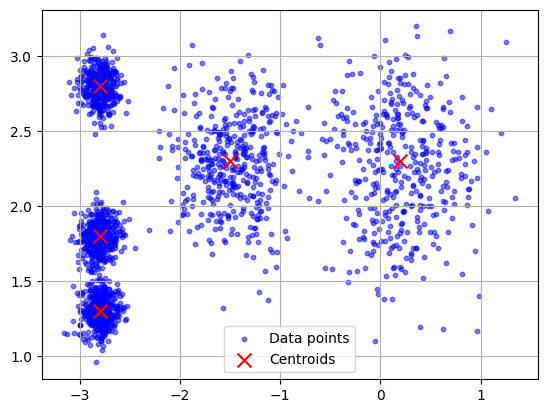

In [24]:
# plot
plt.scatter(X[:, 0], X[:, 1], s=10, c='blue', label="Data points", alpha=0.5)
plt.scatter(blob_centers[:,0], blob_centers[:, 1], c='red', s=100, marker='x', label="Centroids")
plt.legend()
plt.grid(True)
plt.show()

In [36]:
# K-means
k = 5
kmeans = KMeans(n_clusters=k, random_state=1)
y_pred = kmeans.fit_predict(X)

In [37]:
print(y_pred)
print(kmeans.labels_)
print(kmeans.cluster_centers_)

[1 4 0 ... 3 0 4]
[1 4 0 ... 3 0 4]
[[ 0.20876306  2.25551336]
 [-2.80037642  1.30082566]
 [-1.46679593  2.28585348]
 [-2.79290307  2.79641063]
 [-2.80389616  1.80117999]]


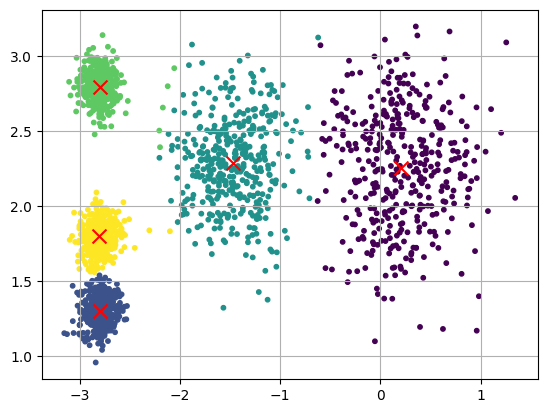

In [38]:
plot_clusters(X, y_pred)
plt.grid(True)

In [39]:
# Elbow Method
kmeans_per_k = [KMeans(n_clusters=k, random_state=1).fit(X) for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]

In [40]:
kmeans_per_k

[KMeans(n_clusters=1, random_state=1),
 KMeans(n_clusters=2, random_state=1),
 KMeans(n_clusters=3, random_state=1),
 KMeans(n_clusters=4, random_state=1),
 KMeans(n_clusters=5, random_state=1),
 KMeans(n_clusters=6, random_state=1),
 KMeans(n_clusters=7, random_state=1),
 KMeans(random_state=1),
 KMeans(n_clusters=9, random_state=1)]

In [41]:
inertias

[3534.8360871670734,
 1149.6140723750264,
 677.2492192493676,
 261.7967778569471,
 211.59853725816828,
 169.64033930193995,
 141.43064318790724,
 119.17981762999554,
 109.28012696508505]

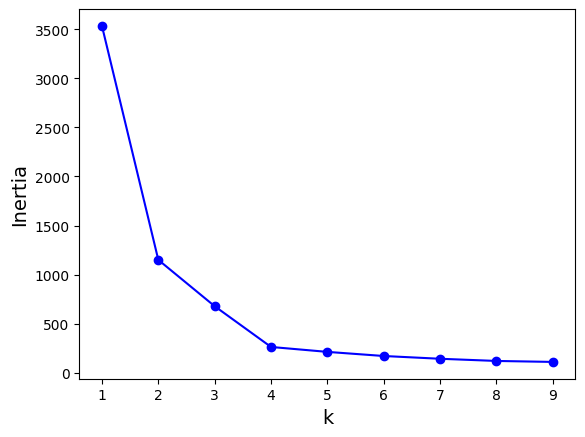

In [42]:
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("k", fontsize=14)
plt.ylabel("Inertia", fontsize=14)
plt.show()

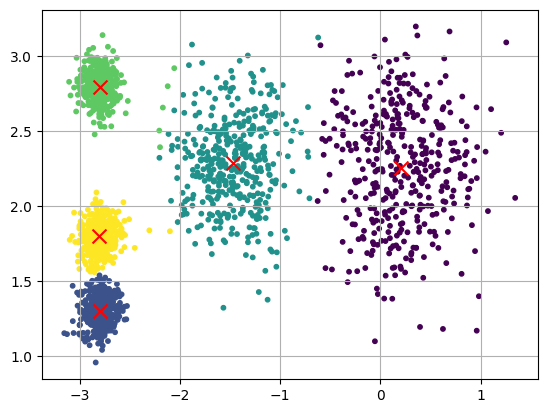

In [43]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=1)
y_pred_k4 = kmeans.fit_predict(X)
plot_clusters(X, y_pred_k4)
plt.grid(True)

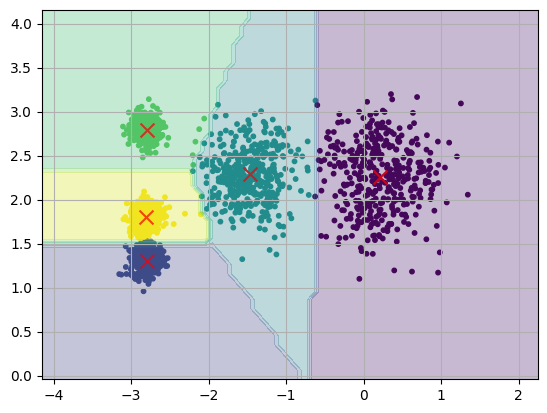

In [44]:
plot_clusters(X, y_pred)

# Create a mesh grid
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

# Predict cluster labels
Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])

# Plot the decision boundaries
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.3)

plt.grid(True)

## Silhouette

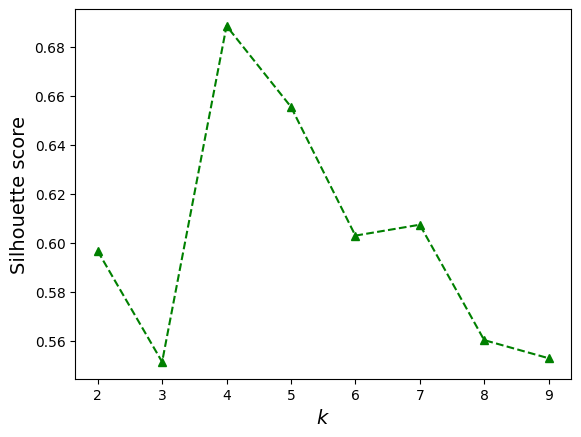

In [45]:
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

plt.plot(range(2, 10), silhouette_scores, "g^--")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.show()

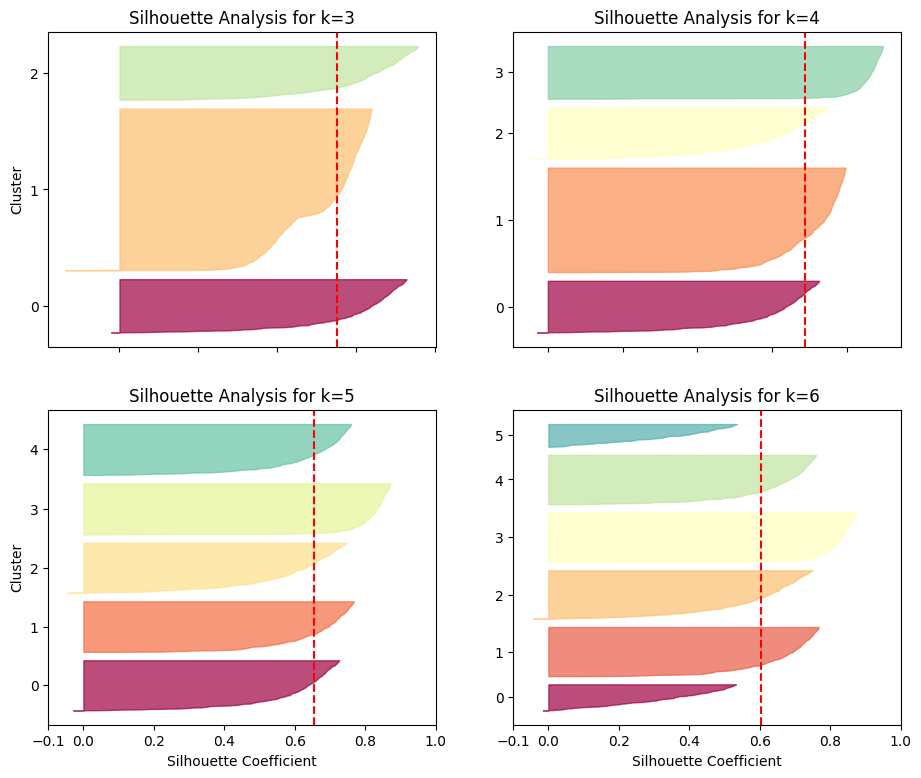

In [46]:
# Step 3: Silhouette Coefficient Visualization for Different Values of k
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter

plt.figure(figsize=(11, 9))  # Create a large figure for subplots

# Loop over values of k (3, 4, 5, 6)
for k in (3, 4, 5, 6):
    plt.subplot(2, 2, k - 2)  # Create a 2x2 grid of plots, one for each k

    # Get predicted labels for the corresponding k
    y_pred = kmeans_per_k[k - 1].labels_

    # Calculate silhouette coefficients for each point
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30  # Define padding between clusters for better visibility
    pos = padding
    ticks = []  # To store tick positions for cluster labels
    for i in range(k):
        # Get silhouette coefficients for cluster i and sort them
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        # Assign a color for each cluster
        color = plt.cm.Spectral(i / k)

        # Fill the silhouette coefficients as a shaded area
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding  # Update position for the next cluster

    # Setting up y-axis ticks and labels for clusters
    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))

    # Adding y-axis label for the first two plots
    if k in (3, 5):
        plt.ylabel("Cluster")

    # Adding x-axis labels for the last two plots
    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    # Plot a vertical line showing the average silhouette score for each k
    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title(f"Silhouette Analysis for k={k}")

plt.show()  # Show the plots
